<a href="https://colab.research.google.com/github/dilathecreator/Financial-Management/blob/main/makine_o%CC%88g%CC%86renmesi_4_hafta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
%%writefile ogrenci_notlari_kirli.csv
calisma_saati,uyku_saati,devamsizlik,kurs_turu,sinav_puani
1,5.5,8,online,42
2,6,6,yuz yuze,50
3.5, ,4,online,65
4,yedi,3,yuz yuze,70
5,7,2, Online,79
25,7,0,online,90
5,7,2,Online,79

Overwriting ogrenci_notlari_kirli.csv


In [8]:
import pandas as pd
df= pd.read_csv("ogrenci_notlari_kirli.csv")


In [9]:
df.head()
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   calisma_saati  7 non-null      float64
 1   uyku_saati     7 non-null      object 
 2   devamsizlik    7 non-null      int64  
 3   kurs_turu      7 non-null      object 
 4   sinav_puani    7 non-null      int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 412.0+ bytes


,0
calisma_saati,0
uyku_saati,0
devamsizlik,0
kurs_turu,0
sinav_puani,0


In [10]:
df.isnull().sum()
df[df["uyku_saati"].isnull()]
df["uyku_saati"].dtype

dtype('O')

In [11]:
df['uyku_saati']= pd.to_numeric(
   df["uyku_saati"],
   errors="coerce"
)
df.info()
uyku_ortalama=df["uyku_saati"].mean()
df["uyku_saati"] = df["uyku_saati"].fillna(uyku_ortalama)
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   calisma_saati  7 non-null      float64
 1   uyku_saati     5 non-null      float64
 2   devamsizlik    7 non-null      int64  
 3   kurs_turu      7 non-null      object 
 4   sinav_puani    7 non-null      int64  
dtypes: float64(2), int64(2), object(1)
memory usage: 412.0+ bytes


,0
calisma_saati,0
uyku_saati,0
devamsizlik,0
kurs_turu,0
sinav_puani,0


In [12]:
df["kurs_turu"] = df["kurs_turu"].str.strip().str.lower()

df["kurs_turu_kod"]=df["kurs_turu"].map({
    "yuz yuze":1,
    "online":0
})
df[["kurs_turu","kurs_turu_kod"]].head()

,kurs_turu,kurs_turu_kod
0,online,0
1,yuz yuze,1
2,online,0
3,yuz yuze,1
4,online,0


In [13]:
df.duplicated().sum ()


np.int64(1)

In [14]:
df=df.drop_duplicates()

In [15]:
df['calisma_saati'].describe()


,calisma_saati
count,6.000000
mean,6.750000
std,9.054005
min,1.000000
25%,2.375000
50%,3.750000
75%,4.750000
max,25.000000


In [16]:
df[df['calisma_saati']>12]


,calisma_saati,uyku_saati,devamsizlik,kurs_turu,sinav_puani,kurs_turu_kod
5,25.0,7.0,0,online,90,0


In [17]:
df=df[df['calisma_saati']<=12]

In [18]:
x=df[[
    "calisma_saati","uyku_saati","devamsizlik","kurs_turu_kod"
]]

y=df["sinav_puani"]
x.head()
y.head()

,sinav_puani
0,42
1,50
2,65
3,70
4,79


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model = KNeighborsRegressor(n_neighbors=3)
model.fit(X_train, y_train)

tahminler = model.predict(X_test)
hata = mean_absolute_error(y_test, tahminler)

print("MAE:", hata)

MAE: 9.0


In [20]:
df.shape
df.columns
df.head()

,calisma_saati,uyku_saati,devamsizlik,kurs_turu,sinav_puani,kurs_turu_kod
0,1.0,5.5,8,online,42,0
1,2.0,6.0,6,yuz yuze,50,1
2,3.5,6.5,4,online,65,0
3,4.0,6.5,3,yuz yuze,70,1
4,5.0,7.0,2,online,79,0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   calisma_saati  5 non-null      float64
 1   uyku_saati     5 non-null      float64
 2   devamsizlik    5 non-null      int64  
 3   kurs_turu      5 non-null      object 
 4   sinav_puani    5 non-null      int64  
 5   kurs_turu_kod  5 non-null      int64  
dtypes: float64(2), int64(3), object(1)
memory usage: 280.0+ bytes


In [24]:
df.describe().round(2)

,calisma_saati,uyku_saati,devamsizlik,sinav_puani,kurs_turu_kod
count,5.0,5.00,5.00,5.00,5.00
mean,3.1,6.30,4.60,61.20,0.40
std,1.6,0.57,2.41,15.02,0.55
min,1.0,5.50,2.00,42.00,0.00
25%,2.0,6.00,3.00,50.00,0.00
50%,3.5,6.50,4.00,65.00,0.00
75%,4.0,6.50,6.00,70.00,1.00
max,5.0,7.00,8.00,79.00,1.00


df.describe çalıştırıldığında tüm sayısal sütunlar için özet tablo oluşturulur, tabloyu okurken özellikler birlikte yorumlanmalırdır.

EDA'nın ikinci adımı; tek bir sayısal değişkenin dağılımını incelemektir.
Histogram, bu amaçla kullanılan temel grafiklerden biridir.


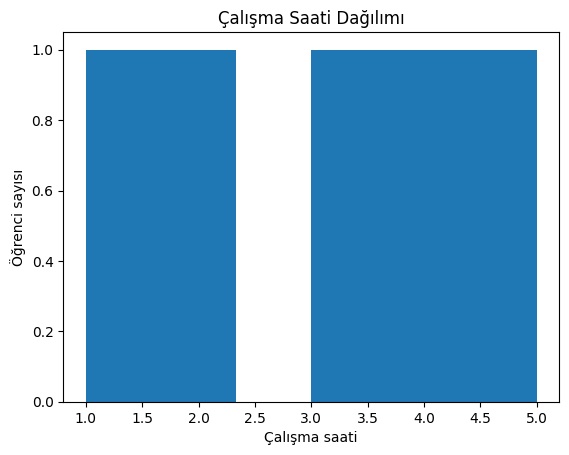

In [25]:
import matplotlib.pyplot as plt

plt.hist(df["calisma_saati"], bins=6)
plt.title("Çalışma Saati Dağılımı")
plt.xlabel("Çalışma saati")
plt.ylabel("Öğrenci sayısı")
plt.show()

**SCATTER** **PLOT**
iki sayısal değişken arasındaki ilişkiyi görmek için kullanılır. her nokta bir gözlemi temsil eder;
x ekseni--> 1. değişken
y ekseni--> 2. değişkeni gösterir.


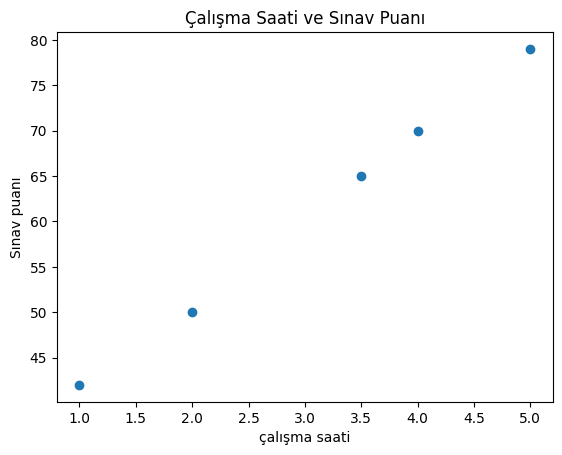

In [26]:
plt.scatter(
    df["calisma_saati"],
    df["sinav_puani"]
)
plt.title("Çalışma Saati ve Sınav Puanı")
plt.xlabel("çalışma saati")
plt.ylabel("Sınav puanı")
plt.show()

In [27]:
df.corr(numeric_only=True).round(2)

,calisma_saati,uyku_saati,devamsizlik,sinav_puani,kurs_turu_kod
calisma_saati,1.00,0.99,-0.99,1.00,-0.06
uyku_saati,0.99,1.00,-0.98,0.98,-0.08
devamsizlik,-0.99,-0.98,1.00,-0.99,-0.04
sinav_puani,1.00,0.98,-0.99,1.00,-0.07
kurs_turu_kod,-0.06,-0.08,-0.04,-0.07,1.00


In [ ]:
plt.boxplot(df["sinav_puani"])
plt.title("Sınav Puanı Boxplot")
plt.ylabel("Sınav Puanı")
plt.show()

aykırı olabilecek gözlemleri hızlıca farketmek için kullanılan temel grafiklerden biridir.